# Module 2 — Du texte aux nombres

> **Objectif** : un réseau de neurones ne manipule que des nombres. Ce module explique comment transformer du texte brut en tenseurs, et pourquoi ce choix (la **tokenisation**) conditionne tout le reste : taille du vocabulaire, longueur des séquences, gestion des mots inconnus, coût de calcul. On code un **BPE** (l'algorithme de tokenisation de GPT) de zéro, on construit des représentations **sac de mots** et **TF-IDF**, et on entraîne un premier classifieur de sentiment.

| | |
|---|---|
| **Durée estimée** | 2 h 30 |
| **Prérequis** | Modules 0 et 1 |
| **Librairies** | `numpy`, `matplotlib`, `scikit-learn` ; `torch`, `transformers` pour les sections finales |

**Plan**

1. Le pipeline texte → tenseur
2. Normalisation : ce qu'on gagne, ce qu'on perd
3. Tokenisation en mots et loi de Zipf
4. Le problème des mots inconnus et la tokenisation en sous-mots
5. BPE de zéro
6. Vocabulaire, tokens spéciaux, identifiants
7. Représenter un document : one-hot, sac de mots, n-grammes, TF-IDF
8. Premier classifieur de sentiment (et ses limites)
9. Évaluer un classifieur : précision, rappel, F1
10. Passage à PyTorch et aux tokenizers de Hugging Face
11. Récapitulatif et exercices

In [1]:
import re
import unicodedata
from collections import Counter, defaultdict

import numpy as np
import matplotlib.pyplot as plt

PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({
    "figure.figsize": (7, 4), "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": "#e6e5e0", "lines.linewidth": 2, "axes.titleweight": "bold",
    "legend.frameon": False, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
})
rng = np.random.default_rng(0)

## 1. Le pipeline texte → tenseur

```
"Ce film n'est pas génial !"
        │  normalisation        → "ce film n'est pas génial !"
        │  tokenisation         → ["ce", "film", "n'", "est", "pas", "génial", "!"]
        │  vocabulaire (str→id) → [  41,    873,   12,   9,    55,   2301,    4 ]
        │  représentation       → sac de mots / TF-IDF   (modules 2)
        ▼                       → vecteurs denses appris (modules 3+)
     tenseur  (B, T) d'entiers long  ──► nn.Embedding ──► (B, T, d)
```

Chaque étape fait des **choix irréversibles** : ce que la normalisation efface, le modèle ne pourra jamais le retrouver ; un mot absent du vocabulaire devient `[UNK]`, et toute son information est perdue.

## 2. Normalisation

### 💡 Intuition

On veut que « Génial », « génial » et « GÉNIAL » soient reconnus comme le même mot, sinon le modèle doit apprendre trois fois la même chose avec trois fois moins d'exemples. Mais chaque normalisation détruit de l'information : « US » (pays) devient « us » (pronom), « Apple » (entreprise) devient « apple » (fruit).

### Le piège Unicode

Un même caractère visuel peut avoir **plusieurs encodages** : « é » peut être un seul point de code (U+00E9) ou « e » suivi d'un accent combinant (U+0065 U+0301). Deux chaînes visuellement identiques sont alors différentes pour l'ordinateur. La normalisation **NFC** (composée) ou **NFD** (décomposée) unifie cela.

In [2]:
s1 = "été"                                   # precomposed characters
s2 = unicodedata.normalize("NFD", s1)       # e + combining accent
print(repr(s1), len(s1), "|", repr(s2), len(s2), "| equal?", s1 == s2)
print("after NFC on both:", unicodedata.normalize("NFC", s1) == unicodedata.normalize("NFC", s2))

def strip_accents(text):
    """NFD then drop combining marks: 'élève' -> 'eleve'. Lossy! (pêche/péché/pèche -> peche)"""
    return "".join(c for c in unicodedata.normalize("NFD", text) if unicodedata.category(c) != "Mn")

def normalize(text, lowercase=True, accents=True):
    text = unicodedata.normalize("NFC", text)
    if lowercase:
        text = text.lower()
    if not accents:
        text = strip_accents(text)
    return re.sub(r"\s+", " ", text).strip()

print(normalize("  Le  PÉCHÉ, la pêche et le pêcher…  "))
print(normalize("  Le  PÉCHÉ, la pêche et le pêcher…  ", accents=False), " <- 3 different words collapse")

'été' 3 | 'été' 5 | equal? False
after NFC on both: True
le péché, la pêche et le pêcher…
le peche, la peche et le pecher…  <- 3 different words collapse


> 🧭 **Règle pratique** : avec les modèles modernes (BERT *cased*, GPT, CamemBERT), on **ne normalise presque rien** à part l'Unicode : on laisse la tokenisation en sous-mots et le modèle gérer casse et accents. La normalisation agressive (minuscules, suppression d'accents, *stemming*, *stopwords*) était cruciale pour les modèles sac de mots ; elle est souvent nuisible pour les Transformers.

## 3. Tokenisation en mots et loi de Zipf

La façon la plus simple de découper un texte : sur les espaces et la ponctuation. Prenons un vrai corpus anglais disponible dans toute installation Python : la documentation des mots-clés et opérateurs (`pydoc_data`), environ 77 000 mots.

In [3]:
from pydoc_data.topics import topics

corpus = " ".join(topics.values())
WORD_RE = re.compile(r"[A-Za-z]+(?:'[a-z]+)?|\d+|[^\sA-Za-z\d]")   # words, numbers, single punctuation

def word_tokenize(text):
    return WORD_RE.findall(text.lower())

tokens = word_tokenize(corpus)
freq = Counter(tokens)
print(f"{len(tokens):,} tokens | {len(freq):,} distinct types")
print("20 most frequent:", freq.most_common(20))

145,174 tokens | 3,516 distinct types
20 most frequent: [('-', 17930), ('"', 9203), ('.', 6033), ('_', 5864), ('the', 5291), ('*', 4515), (',', 4039), ('=', 3785), ('(', 2988), (')', 2988), ('a', 2211), ('is', 2072), (':', 1834), ('|', 1646), ('of', 1590), ('in', 1539), ("'", 1459), ('to', 1456), ('>', 1244), ('and', 1186)]


### 📐 La loi de Zipf

Dans tout corpus de langue naturelle, la fréquence $f$ du mot de rang $r$ suit approximativement
$$
f(r) \propto \frac{1}{r^{\alpha}}, \qquad \alpha\approx 1
$$
soit une **droite de pente $-\alpha$ en échelle log-log**. Conséquences pratiques énormes :
- quelques mots très fréquents (« the », « , », « of ») représentent une grande partie des tokens ;
- une **longue traîne** de mots rares : une grande partie des types (souvent 40 à 60 % dans un grand corpus) n'apparaissent qu'**une seule fois** (*hapax*). Un modèle les verra trop peu pour apprendre quoi que ce soit ;
- quelle que soit la taille du vocabulaire, il restera des mots inconnus au test.

hapax (types seen once): 852 = 24% of the vocabulary


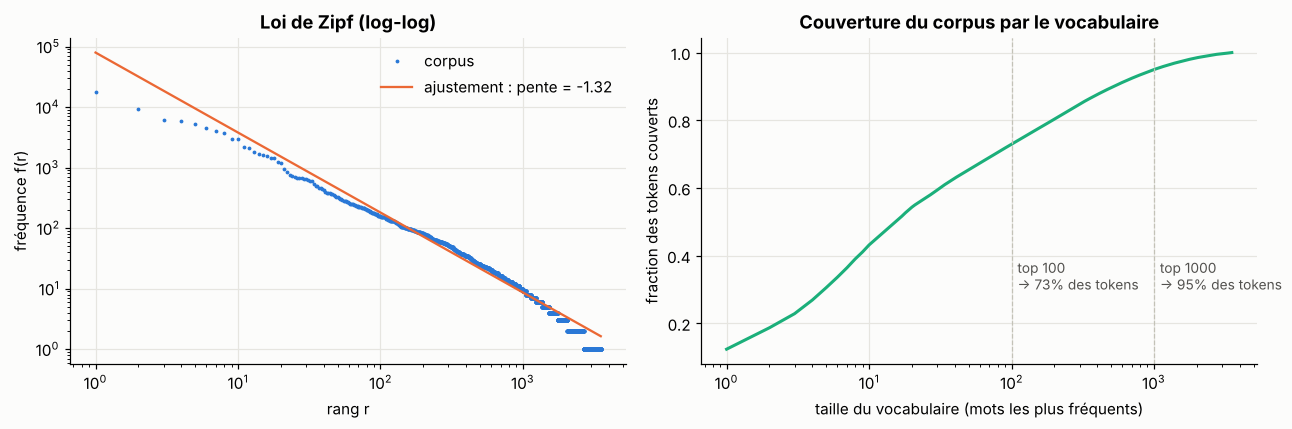

In [4]:
counts = np.array(sorted(freq.values(), reverse=True))
ranks = np.arange(1, len(counts) + 1)
slope, intercept = np.polyfit(np.log(ranks[:2000]), np.log(counts[:2000]), 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].loglog(ranks, counts, ".", ms=3, color=PALETTE[0], label="corpus")
axes[0].loglog(ranks, np.exp(intercept) * ranks**slope, color=PALETTE[1], lw=1.5, label=f"ajustement : pente = {slope:.2f}")
axes[0].set_xlabel("rang r"); axes[0].set_ylabel("fréquence f(r)"); axes[0].set_title("Loi de Zipf (log-log)"); axes[0].legend()

coverage = np.cumsum(counts) / counts.sum()
axes[1].semilogx(ranks, coverage, color=PALETTE[2])
for k in [100, 1000]:
    axes[1].axvline(k, color="#c3c2b7", lw=0.8, ls="--")
    axes[1].text(k * 1.1, 0.3, f"top {k}\n→ {coverage[k-1]:.0%} des tokens", fontsize=9, color="#52514e")
axes[1].set_xlabel("taille du vocabulaire (mots les plus fréquents)"); axes[1].set_ylabel("fraction des tokens couverts")
axes[1].set_title("Couverture du corpus par le vocabulaire")
plt.tight_layout(); plt.show()
hapax = sum(1 for c in freq.values() if c == 1)
print(f"hapax (types seen once): {hapax:,} = {hapax / len(freq):.0%} of the vocabulary")

Notre corpus est atypique : de la documentation technique, très répétitive, où la ponctuation (`-`, `"`, `.`) domine le haut du classement. D'où une pente plus raide que $-1$ et « seulement » ~25 % d'hapax. La forme générale (droite en log-log, longue traîne) est pourtant bien là : c'est la robustesse de la loi de Zipf.

## 4. Mots inconnus et tokenisation en sous-mots

### 💡 Intuition

Trois granularités possibles :

| Granularité | Vocabulaire | Longueur des séquences | Mots inconnus | Sens par token |
|---|---|---|---|---|
| **Caractères** | ~100 | très longue | aucun | quasi nul |
| **Mots** | 100 k – 1 M | courte | nombreux (`[UNK]`) | riche |
| **Sous-mots** (BPE, WordPiece, Unigram) | 30 k – 250 k | moyenne | aucun (repli sur les caractères/octets) | bon compromis |

Les sous-mots exploitent la **morphologie** : « incompréhensiblement » = « in » + « compréhens » + « ible » + « ment ». Un mot jamais vu est découpé en morceaux connus. Les mots fréquents restent entiers, les rares sont décomposés. C'est la tokenisation de **tous** les modèles de langue modernes.

In [5]:
# How many test words are unknown with a word-level vocabulary built on train?
words_doc = list(topics.values())
split = int(0.8 * len(words_doc))
train_tokens = word_tokenize(" ".join(words_doc[:split]))
test_tokens = word_tokenize(" ".join(words_doc[split:]))
train_freq = Counter(train_tokens)
for min_freq in [1, 2, 5]:
    vocab = {w for w, c in train_freq.items() if c >= min_freq}
    oov = np.mean([t not in vocab for t in test_tokens])
    print(f"min_freq={min_freq}: vocab size {len(vocab):6,} | OOV rate on test = {oov:.1%}")

min_freq=1: vocab size  2,819 | OOV rate on test = 2.5%
min_freq=2: vocab size  1,981 | OOV rate on test = 3.6%
min_freq=5: vocab size  1,130 | OOV rate on test = 5.8%


## 5. Byte-Pair Encoding (BPE) de zéro

### 📐 L'algorithme (Sennrich et al., 2016)

**Entraînement** :
1. Découper chaque mot en caractères, avec un marqueur de fin de mot `</w>` (pour distinguer « est » en fin de mot de « est » dans « estomac »).
2. Compter toutes les **paires de symboles adjacents**, pondérées par la fréquence des mots.
3. **Fusionner** la paire la plus fréquente en un nouveau symbole ; l'ajouter à la liste des fusions.
4. Répéter jusqu'à atteindre la taille de vocabulaire voulue.

**Encodage d'un mot nouveau** : partir des caractères et appliquer les fusions apprises **dans l'ordre où elles ont été apprises** (la fusion de rang le plus bas d'abord).

Taille du vocabulaire final = nombre de caractères de base + nombre de fusions.

**Variante byte-level (GPT-2, GPT-4, LLaMA)** : on part des **256 octets** UTF-8 au lieu des caractères. Tout texte, dans toute langue, emojis compris, est alors encodable sans aucun `[UNK]`.

In [6]:
def train_bpe(word_freqs, num_merges, verbose=0):
    """BPE training with incremental pair counts (fast enough for ~10^4 distinct words)."""
    words = [list(w) + ["</w>"] for w in word_freqs]
    freqs = list(word_freqs.values())
    pair_counts, where = Counter(), defaultdict(set)
    for i, w in enumerate(words):
        for pair in zip(w, w[1:]):
            pair_counts[pair] += freqs[i]
            where[pair].add(i)

    merges = []
    for step in range(num_merges):
        if not pair_counts:
            break
        best = max(pair_counts, key=pair_counts.get)
        if pair_counts[best] < 2:
            break
        merges.append(best)
        if step < verbose:
            print(f"merge {step:3d}: {best[0]!r:>8} + {best[1]!r:<8} -> {best[0] + best[1]!r:<12} (count {pair_counts[best]})")
        merged = best[0] + best[1]
        for i in list(where[best]):
            w, f = words[i], freqs[i]
            for pair in zip(w, w[1:]):                       # remove this word's old pairs
                pair_counts[pair] -= f
                if pair_counts[pair] <= 0:
                    del pair_counts[pair]
                where[pair].discard(i)
            new_w, j = [], 0
            while j < len(w):                                # apply the merge inside the word
                if j < len(w) - 1 and w[j] == best[0] and w[j + 1] == best[1]:
                    new_w.append(merged); j += 2
                else:
                    new_w.append(w[j]); j += 1
            words[i] = new_w
            for pair in zip(new_w, new_w[1:]):               # add the new pairs
                pair_counts[pair] += f
                where[pair].add(i)
    return merges


def bpe_encode_word(word, merge_rank, max_rank=None):
    """Greedy encoding: repeatedly apply the earliest-learned merge present in the word."""
    symbols = list(word) + ["</w>"]
    while len(symbols) > 1:
        ranked = [(merge_rank.get(p, np.inf), k) for k, p in enumerate(zip(symbols, symbols[1:]))]
        r, k = min(ranked)
        if r == np.inf or (max_rank is not None and r >= max_rank):
            break
        symbols = symbols[:k] + [symbols[k] + symbols[k + 1]] + symbols[k + 2:]
    return symbols


word_freqs = Counter(t for t in train_tokens if t.isalpha())
merges = train_bpe(word_freqs, num_merges=3000, verbose=15)
merge_rank = {m: r for r, m in enumerate(merges)}
print(f"\nlearned {len(merges)} merges")

merge   0:      'e' + '</w>'   -> 'e</w>'      (count 9790)
merge   1:      's' + '</w>'   -> 's</w>'      (count 6953)
merge   2:      't' + 'h'      -> 'th'         (count 5731)
merge   3:      't' + '</w>'   -> 't</w>'      (count 4937)
merge   4:      'n' + '</w>'   -> 'n</w>'      (count 4835)
merge   5:      'd' + '</w>'   -> 'd</w>'      (count 3938)
merge   6:      'e' + 'r'      -> 'er'         (count 3489)
merge   7:     'th' + 'e</w>'  -> 'the</w>'    (count 3323)
merge   8:      'i' + 'n'      -> 'in'         (count 3210)
merge   9:      'a' + 't'      -> 'at'         (count 2622)
merge  10:      'o' + 'r'      -> 'or'         (count 2526)
merge  11:      'a' + 'l'      -> 'al'         (count 2264)
merge  12:      'i' + 'o'      -> 'io'         (count 2233)
merge  13:      'e' + 'd</w>'  -> 'ed</w>'     (count 2165)
merge  14:      'a' + 'r'      -> 'ar'         (count 2155)

learned 3000 merges


Les premières fusions sont des **bigrammes de lettres très fréquents** (« e » + « </w> », « t » + « h », « th » + « e »…). Puis apparaissent des morceaux de mots, puis des mots entiers. Testons sur des mots, dont certains absents du corpus d'entraînement :

In [7]:
for w in ["the", "function", "functions", "dysfunctional", "tokenization", "parameterized", "unbelievably", "zxqv"]:
    seen = "vu" if w in word_freqs else "jamais vu"
    print(f"{w:16s} ({seen:9s}) -> {bpe_encode_word(w, merge_rank)}")

the              (vu       ) -> ['the</w>']
function         (vu       ) -> ['function</w>']
functions        (vu       ) -> ['functions</w>']
dysfunctional    (jamais vu) -> ['dy', 's', 'func', 'tional</w>']
tokenization     (jamais vu) -> ['tok', 'en', 'iz', 'ation</w>']
parameterized    (jamais vu) -> ['parame', 'ter', 'ized</w>']
unbelievably     (jamais vu) -> ['un', 'be', 'li', 'ev', 'ab', 'ly</w>']
zxqv             (jamais vu) -> ['z', 'x', 'q', 'v', '</w>']


### 📊 Le compromis taille de vocabulaire / longueur des séquences

Plus on fait de fusions, plus le vocabulaire grossit et plus les séquences raccourcissent. Mesurons le nombre moyen de tokens par mot sur le **jeu de test** :

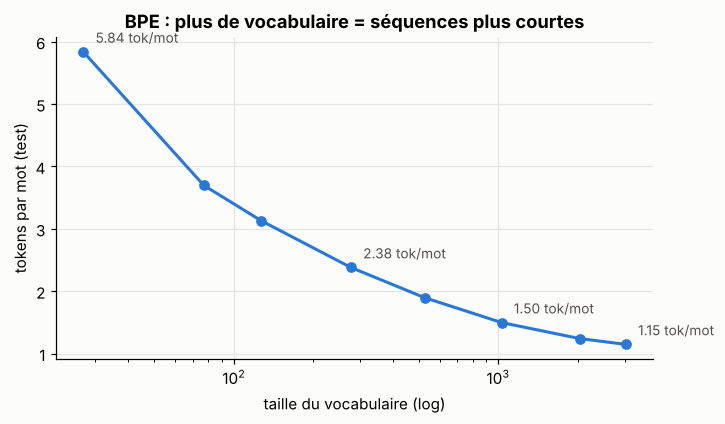

In [8]:
test_words = [t for t in test_tokens if t.isalpha()]
n_base = len({c for w in word_freqs for c in w}) + 1      # characters + </w>
results = []
for k in [0, 50, 100, 250, 500, 1000, 2000, 3000]:
    n_tok = sum(len(bpe_encode_word(w, merge_rank, max_rank=k)) for w in test_words)
    results.append((n_base + k, n_tok / len(test_words)))
results = np.array(results)

plt.figure(figsize=(7, 3.8))
plt.plot(results[:, 0], results[:, 1], "o-", color=PALETTE[0])
for v, t in results[[0, 3, 5, 7]]:
    plt.annotate(f"{t:.2f} tok/mot", (v, t), textcoords="offset points", xytext=(8, 6), fontsize=9, color="#52514e")
plt.xscale("log"); plt.xlabel("taille du vocabulaire (log)"); plt.ylabel("tokens par mot (test)")
plt.title("BPE : plus de vocabulaire = séquences plus courtes")
plt.show()

> ⚖️ **Pourquoi ce compromis compte** : le coût de l'attention d'un Transformer croît en $O(T^2)$ avec la longueur $T$ des séquences (module 6), tandis que la matrice d'embeddings et la couche de sortie croissent en $O(V\cdot d)$ avec la taille $V$ du vocabulaire. GPT-2 : $V=50\,257$ ; LLaMA 2 : $32\,000$ ; LLaMA 3 et GPT-4 : ~$100$–$128\,000$ (meilleure compression du code et des langues non anglaises). Pour les **protéines** (module 9), la plupart des modèles (ESM) gardent au contraire une tokenisation **par acide aminé** ($V\approx 33$).

**WordPiece** (BERT) et **Unigram** (SentencePiece, T5, CamemBERT) sont des variantes : WordPiece choisit la fusion qui maximise la vraisemblance du corpus plutôt que la fréquence brute ; Unigram part d'un grand vocabulaire et **élague** les sous-mots les moins utiles selon un modèle de langue unigramme.

## 6. Vocabulaire, tokens spéciaux, identifiants

Un vocabulaire est une bijection *token ↔ entier*, avec des **tokens spéciaux** réservés :

| Token | Rôle |
|---|---|
| `[PAD]` | remplissage des séquences courtes (masqué, module 1) |
| `[UNK]` | token inconnu (n'existe plus avec un BPE byte-level) |
| `[BOS]` / `[EOS]` (`<s>`, `</s>`) | début / fin de séquence (génération, module 4) |
| `[CLS]` | token dont la représentation résume la phrase (BERT, module 7) |
| `[SEP]` | séparateur entre deux segments |
| `[MASK]` | token masqué à prédire (pré-entraînement de BERT, module 7) |

In [9]:
class Vocab:
    def __init__(self, tokens, min_freq=1, specials=("[PAD]", "[UNK]", "[BOS]", "[EOS]")):
        counts = Counter(tokens)
        self.itos = list(specials) + sorted(t for t, c in counts.items() if c >= min_freq and t not in specials)
        self.stoi = {t: i for i, t in enumerate(self.itos)}
        self.pad_id, self.unk_id = self.stoi["[PAD]"], self.stoi["[UNK]"]

    def __len__(self):
        return len(self.itos)

    def encode(self, toks, add_bos_eos=False):
        ids = [self.stoi.get(t, self.unk_id) for t in toks]
        return [self.stoi["[BOS]"]] + ids + [self.stoi["[EOS]"]] if add_bos_eos else ids

    def decode(self, ids):
        return [self.itos[i] for i in ids]


voc = Vocab(train_tokens, min_freq=2)
ids = voc.encode(word_tokenize("The lambda expression yields a frobnicated value."), add_bos_eos=True)
print(len(voc), ids)
print(voc.decode(ids))

1985 [2, 1784, 1012, 700, 1965, 102, 1, 1901, 17, 3]
['[BOS]', 'the', 'lambda', 'expression', 'yields', 'a', '[UNK]', 'value', '.', '[EOS]']


## 7. Représenter un document entier

Pour classer un document, il faut un vecteur **de taille fixe**, quelle que soit la longueur du texte.

### 7.1 Sac de mots (*bag of words*)

On compte les occurrences de chaque mot du vocabulaire : le document $d$ devient $x_d\in\mathbb N^{V}$. L'ordre des mots est **perdu** : « le chien mord l'homme » = « l'homme mord le chien ». Les vecteurs sont **creux** (*sparse*) : presque toutes les composantes sont nulles.

**N-grammes** : on ajoute les paires (bigrammes), triplets… de mots consécutifs. « pas bon » devient une caractéristique à part entière, ce qui capture un peu d'ordre local, au prix d'un vocabulaire qui explose.

### 7.2 TF-IDF

### 💡 Intuition

Un mot présent dans **tous** les documents (« le », « est ») ne dit rien sur un document particulier. Un mot fréquent **dans ce document** mais **rare ailleurs** est très informatif. TF-IDF pondère chaque mot par ces deux critères.

### 📐 Maths

$$
\text{tfidf}(t,d) = \underbrace{\text{tf}(t,d)}_{\text{nombre d'occurrences de } t \text{ dans } d}\times\underbrace{\left(\ln\frac{1+N}{1+\text{df}(t)} + 1\right)}_{\text{idf}(t)}
$$

où $N$ est le nombre de documents et $\text{df}(t)$ le nombre de documents contenant $t$ (c'est la variante « lissée » de scikit-learn ; le $+1$ évite les divisions par zéro et garde un poids non nul aux mots présents partout). Chaque vecteur document est ensuite **normalisé** en norme L2, pour que les longs documents ne dominent pas.

La **similarité cosinus** compare deux documents indépendamment de leur longueur :
$$
\cos(x_a, x_b) = \frac{x_a\cdot x_b}{\lVert x_a\rVert\,\lVert x_b\rVert}
$$
(avec des vecteurs déjà normalisés, c'est un simple produit scalaire.)

In [10]:
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

docs = ["le chat dort sur le canapé",
        "le chien dort dans le jardin",
        "le chat et le chien jouent dans le jardin"]

# --- by hand ---
tok_docs = [d.split() for d in docs]
terms = sorted({t for d in tok_docs for t in d})
tf = np.array([[d.count(t) for t in terms] for d in tok_docs], dtype=float)
df = (tf > 0).sum(0)
idf = np.log((1 + len(docs)) / (1 + df)) + 1
X_manual = tf * idf
X_manual /= np.linalg.norm(X_manual, axis=1, keepdims=True)

# --- scikit-learn ---
vec = TfidfVectorizer(token_pattern=r"\S+")
X_sk = vec.fit_transform(docs).toarray()
print("same terms order:", list(vec.get_feature_names_out()) == terms, "| max abs diff:", np.abs(X_manual - X_sk).max())
for t, i_ in zip(terms, idf):
    print(f"  idf({t!r:10}) = {i_:.3f}")

same terms order: True | max abs diff: 1.1102230246251565e-16
  idf('canapé'  ) = 1.693
  idf('chat'    ) = 1.288
  idf('chien'   ) = 1.288
  idf('dans'    ) = 1.288
  idf('dort'    ) = 1.288
  idf('et'      ) = 1.693
  idf('jardin'  ) = 1.288
  idf('jouent'  ) = 1.693
  idf('le'      ) = 1.000
  idf('sur'     ) = 1.693


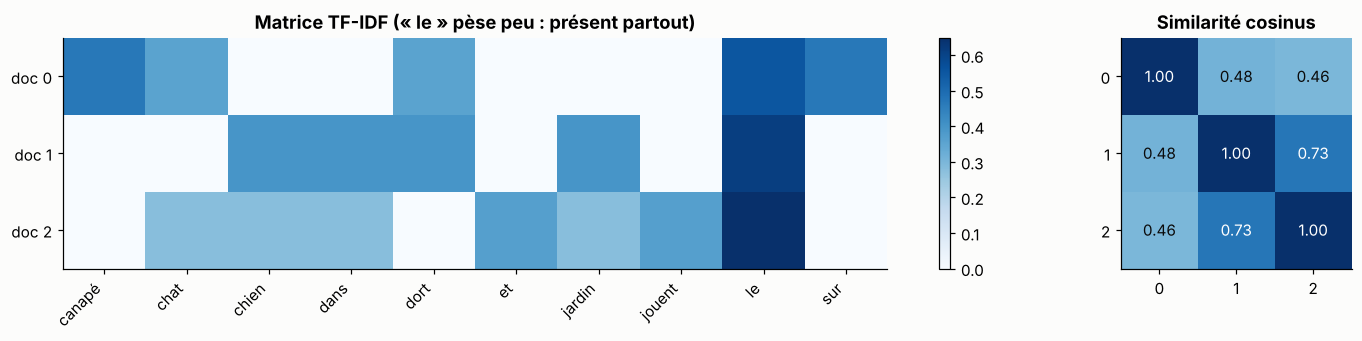

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.2), gridspec_kw={"width_ratios": [3, 1]})
im = axes[0].imshow(X_sk, cmap="Blues", aspect="auto")
axes[0].set_xticks(range(len(terms))); axes[0].set_xticklabels(terms, rotation=45, ha="right")
axes[0].set_yticks(range(3)); axes[0].set_yticklabels([f"doc {i}" for i in range(3)])
axes[0].set_title("Matrice TF-IDF (« le » pèse peu : présent partout)"); axes[0].grid(False)
plt.colorbar(im, ax=axes[0])
S = X_sk @ X_sk.T
axes[1].imshow(S, cmap="Blues", vmin=0, vmax=1)
for (i, j), v in np.ndenumerate(S):
    axes[1].text(j, i, f"{v:.2f}", ha="center", va="center", color="white" if v > 0.6 else "#0b0b0b")
axes[1].set_title("Similarité cosinus"); axes[1].grid(False)
axes[1].set_xticks(range(3)); axes[1].set_yticks(range(3))
plt.tight_layout(); plt.show()

## 8. Premier classifieur de sentiment

### Les données

Pour que ce notebook tourne **sans téléchargement**, on génère un petit corpus de critiques en français à partir de gabarits. Il est volontairement construit pour contenir les difficultés classiques : **négation** (« n'est pas excellent »), **contraste** (« …, mais la fin est ratée »), intensifieurs et phrases neutres.

> 📦 **Avec de vraies données** : le jeu *Allociné* (200 000 critiques de films en français) s'obtient en deux lignes avec Hugging Face : `from datasets import load_dataset; ds = load_dataset("allocine")`. Tout le code de cette section s'applique tel quel en remplaçant `texts`/`labels`. En anglais : `load_dataset("imdb")`.

In [12]:
SUBJECTS = ["le film", "ce film", "le scénario", "le jeu des acteurs", "le montage", "ce restaurant",
            "le service", "le dessert", "ce livre", "le dénouement", "le décor", "ce spectacle"]
POS = ["excellent", "magnifique", "génial", "drôle", "captivant", "réussi", "émouvant", "brillant", "savoureux", "agréable"]
NEG = ["ennuyeux", "décevant", "raté", "médiocre", "lent", "fade", "confus", "prévisible", "mauvais", "pénible"]
INTENS = ["", "", "vraiment ", "très ", "assez ", "franchement ", "plutôt "]
NEG_INTENS = ["", "", "vraiment ", "très ", "si ", "franchement ", "tellement "]   # intensifiers that sound right after "pas"
NEUTRAL = ["je l'ai vu samedi.", "nous étions quatre.", "la salle était pleine.", "il a duré deux heures.",
           "j'y suis allé avec ma sœur.", "c'était un mardi soir."]
CLOSING = {1: ["bref, à voir !", "je recommande.", "j'y retournerai."], -1: ["bref, à éviter.", "je ne recommande pas.", "quelle perte de temps."]}


def make_sentence(r):
    s = r.choice(SUBJECTS)
    pol = r.choice([1, -1])
    adj = r.choice(POS if pol == 1 else NEG)
    kind = r.random()
    if kind < 0.5:                                           # plain statement
        return f"{s} est {r.choice(INTENS)}{adj}.", pol
    if kind < 0.8:                                           # negation flips polarity
        return f"{s} n'est pas {r.choice(NEG_INTENS)}{adj}.", -pol
    adj2 = r.choice(NEG if pol == 1 else POS)                # contrast: the clause after "mais" wins
    s2 = r.choice(SUBJECTS)
    return f"{s} est {adj}, mais {s2} est {r.choice(INTENS)}{adj2}.", -pol


def make_review(r):
    parts, score = [], 0
    for _ in range(r.integers(1, 3)):
        sent, pol = make_sentence(r)
        parts.append(sent); score += pol
    if r.random() < 0.5:
        parts.insert(r.integers(0, len(parts) + 1), r.choice(NEUTRAL))
    if score == 0:                                           # break ties with an explicit closing sentence
        score = r.choice([1, -1])
        parts.append(r.choice(CLOSING[score]))
    elif r.random() < 0.3:
        parts.append(r.choice(CLOSING[int(np.sign(score))]))
    text = " ".join(p[0].upper() + p[1:] for p in parts)     # capitalize every sentence
    return text, int(score > 0)


r = np.random.default_rng(42)
data = [make_review(r) for _ in range(3000)]
texts, labels = [t for t, _ in data], np.array([l for _, l in data])
for t, l in data[:6]:
    print(("😀" if l else "😞"), t)
print("\npositive fraction:", labels.mean().round(3))

😀 Le dénouement est lent, mais ce livre est excellent.
😞 C'était un mardi soir. Ce livre est fade.
😞 Le dénouement est lent. C'était un mardi soir.
😞 Ce film est prévisible, mais ce restaurant est plutôt drôle. Je l'ai vu samedi. Ce livre est prévisible. Quelle perte de temps.
😀 Nous étions quatre. Ce livre est plutôt agréable. Le montage est très captivant.
😞 Ce spectacle n'est pas franchement magnifique. J'y suis allé avec ma sœur.

positive fraction: 0.494


### Entraînement : TF-IDF + régression logistique

La régression logistique, c'est **un seul neurone sigmoïde** (module 0) entraîné avec l'entropie croisée binaire, sur les vecteurs TF-IDF : $p(\text{positif}\mid d) = \sigma(w^\top x_d + b)$. Chaque poids $w_t$ s'interprète directement : positif = le mot $t$ pousse vers « positif ».

In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X_tr_txt, X_te_txt, y_tr, y_te = train_test_split(texts, labels, test_size=0.25, random_state=0, stratify=labels)

def fit_eval(ngram_range):
    vec = TfidfVectorizer(ngram_range=ngram_range, token_pattern=r"(?u)\b\w+\b", sublinear_tf=True)
    Xtr = vec.fit_transform(X_tr_txt)            # fit the vocabulary & idf on TRAIN only
    Xte = vec.transform(X_te_txt)                # never refit on test (data leakage)
    clf = LogisticRegression(C=10, max_iter=2000).fit(Xtr, y_tr)
    acc = accuracy_score(y_te, clf.predict(Xte))
    return vec, clf, acc, Xtr.shape[1]

vec1, clf1, acc1, nf1 = fit_eval((1, 1))
vec2, clf2, acc2, nf2 = fit_eval((1, 2))
vec3, clf3, acc3, nf3 = fit_eval((1, 3))
print(f"unigrams        : {nf1:5d} features | test accuracy {acc1:.3f}")
print(f"uni + bigrams   : {nf2:5d} features | test accuracy {acc2:.3f}")
print(f"uni + bi + tri  : {nf3:5d} features | test accuracy {acc3:.3f}")

unigrams        :    85 features | test accuracy 0.780
uni + bigrams   :   605 features | test accuracy 0.935
uni + bi + tri  :  2944 features | test accuracy 0.985


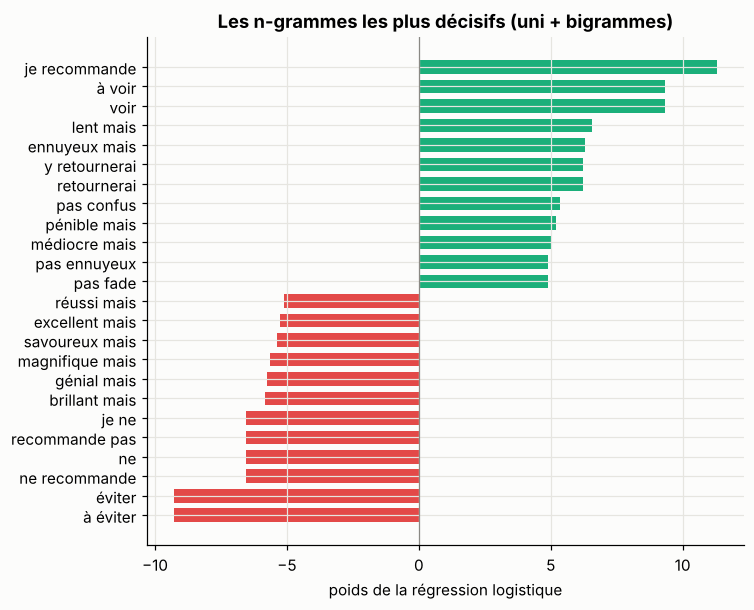

In [14]:
def plot_top_weights(vec, clf, k=12, title=""):
    names = vec.get_feature_names_out()
    w = clf.coef_[0]
    idx = np.r_[np.argsort(w)[:k], np.argsort(w)[-k:]]
    plt.figure(figsize=(7, 6))
    plt.barh(range(len(idx)), w[idx], color=[PALETTE[7] if v < 0 else PALETTE[2] for v in w[idx]], height=0.7)
    plt.yticks(range(len(idx)), names[idx]); plt.axvline(0, color="#8a8984", lw=0.8)
    plt.title(title); plt.xlabel("poids de la régression logistique")
    plt.show()

plot_top_weights(vec2, clf2, title="Les n-grammes les plus décisifs (uni + bigrammes)")

Regarde quels bigrammes apparaissent : « pas excellent », « mais le »… Le modèle a appris que la négation inverse le sens **seulement parce qu'on lui a donné des bigrammes**. Il ne « comprend » rien : il mémorise des combinaisons locales.

### 🔍 Analyse d'erreurs

La première chose à faire après un score : **lire les erreurs**.

In [15]:
def show_errors(vec, clf, n=8):
    Xte = vec.transform(X_te_txt)
    proba = clf.predict_proba(Xte)[:, 1]
    wrong = np.where((proba > 0.5) != y_te)[0]
    print(f"{len(wrong)} errors out of {len(y_te)}")
    for i in wrong[:n]:
        print(f"  true={'pos' if y_te[i] else 'neg'} p(pos)={proba[i]:.2f} | {X_te_txt[i]}")

print("=== unigram model ===");  show_errors(vec1, clf1)
print("\n=== uni+bigram model ==="); show_errors(vec2, clf2)

=== unigram model ===
165 errors out of 750
  true=neg p(pos)=0.64 | C'était un mardi soir. Le jeu des acteurs n'est pas franchement excellent.
  true=pos p(pos)=0.32 | Ce spectacle n'est pas tellement pénible.
  true=pos p(pos)=0.43 | Le dénouement n'est pas décevant.
  true=neg p(pos)=0.56 | Ce livre est vraiment confus.
  true=neg p(pos)=0.56 | Le jeu des acteurs est plutôt lent.
  true=pos p(pos)=0.40 | Ce film n'est pas confus.
  true=pos p(pos)=0.26 | Ce livre n'est pas franchement médiocre. Le dessert n'est pas si confus. Nous étions quatre.
  true=neg p(pos)=0.56 | Le dessert n'est pas très brillant. Il a duré deux heures.

=== uni+bigram model ===
49 errors out of 750
  true=neg p(pos)=0.78 | C'était un mardi soir. Le jeu des acteurs n'est pas franchement excellent.
  true=neg p(pos)=0.65 | Ce livre est vraiment confus.
  true=pos p(pos)=0.48 | Le service est raté, mais ce spectacle est franchement réussi.
  true=pos p(pos)=0.38 | Ce livre n'est pas très décevant.
  true=pos p

In [16]:
probe = ["Le film n'est pas mauvais.", "Le film n'est pas excellent.",
         "Le film est excellent, mais le service est pénible.",
         "Le service est pénible, mais le film est excellent.",
         "Le film n'est pas du tout à la hauteur.", "Ce film est un chef-d'œuvre."]
for m_name, (vec, clf) in {"unigrams": (vec1, clf1), "uni+bigrams": (vec2, clf2)}.items():
    print(m_name)
    for s, p in zip(probe, clf.predict_proba(vec.transform(probe))[:, 1]):
        print(f"   p(pos)={p:.2f}  {s}")

unigrams
   p(pos)=0.31  Le film n'est pas mauvais.
   p(pos)=0.74  Le film n'est pas excellent.
   p(pos)=0.44  Le film est excellent, mais le service est pénible.
   p(pos)=0.44  Le service est pénible, mais le film est excellent.
   p(pos)=0.51  Le film n'est pas du tout à la hauteur.
   p(pos)=0.42  Ce film est un chef-d'œuvre.
uni+bigrams
   p(pos)=0.83  Le film n'est pas mauvais.
   p(pos)=0.05  Le film n'est pas excellent.
   p(pos)=0.08  Le film est excellent, mais le service est pénible.
   p(pos)=0.87  Le service est pénible, mais le film est excellent.
   p(pos)=0.32  Le film n'est pas du tout à la hauteur.
   p(pos)=0.53  Ce film est un chef-d'œuvre.


> ⚠️ **Lecture critique** :
> - **Unigrammes** : « n'est pas mauvais » est jugé négatif et « n'est pas excellent » positif : sans ordre, la négation est invisible. Les deux phrases avec « mais » contiennent **exactement les mêmes mots** : le modèle leur donne forcément la même probabilité.
> - **Bigrammes** : ils « résolvent » ces cas, mais par une astuce locale. Le bigramme « excellent mais » (la virgule est supprimée par la tokenisation) encode quel adjectif précède « mais ». Dès que la structure change (« n'est pas *franchement* excellent », négation à distance 2), le bigramme ne suffit plus : regarde les erreurs restantes ci-dessus. C'est pour cela que les trigrammes montent à ~98 % **sur ces gabarits**.
> - « chef-d'œuvre » et « pas du tout à la hauteur » n'existent pas dans le corpus d'entraînement : prédiction proche de 0.5, le modèle ne **généralise pas** au-delà des n-grammes vus. C'est la motivation des **embeddings** (module 3) : des mots de sens proche auront des vecteurs proches.
> - Un score élevé sur des données synthétiques ne dit rien sur des critiques réelles, bien plus variées. Avec les n-grammes, le nombre de caractéristiques explose (×30 ici des unigrammes aux trigrammes) alors que chaque trigramme est vu rarement : sur de vraies données, le gain des trigrammes est souvent faible.

## 9. Évaluer un classifieur

La précision globale (*accuracy*) est trompeuse dès que les classes sont déséquilibrées : sur un jeu avec 95 % de négatifs, prédire toujours « négatif » donne 95 %. Pour chaque classe $c$, on compte vrais positifs (TP), faux positifs (FP), faux négatifs (FN) :

$$
\text{précision}_c = \frac{TP}{TP + FP}\qquad \text{rappel}_c = \frac{TP}{TP+FN}\qquad F_1 = \frac{2\cdot\text{précision}\cdot\text{rappel}}{\text{précision}+\text{rappel}}
$$

- **Précision** : « quand je dis $c$, ai-je raison ? »
- **Rappel** : « parmi tous les vrais $c$, combien en ai-je trouvé ? »
- **F1** : moyenne harmonique, punit un déséquilibre entre les deux.
- **Macro-F1** : moyenne simple des F1 par classe (chaque classe compte autant, adapté aux classes rares) ; **micro-F1** : calculé sur les comptes globaux (en mono-étiquette, égal à l'accuracy).

Ces métriques reviendront pour la **classification de tokens** (reconnaissance d'entités, délimitation de régions dans une séquence, modules 7 à 9), où l'on mesure aussi le F1 **au niveau des entités** (une entité n'est correcte que si ses deux bornes et son type sont justes).

              precision    recall  f1-score   support

     négatif      0.785     0.779     0.782       380
     positif      0.775     0.781     0.778       370

    accuracy                          0.780       750
   macro avg      0.780     0.780     0.780       750
weighted avg      0.780     0.780     0.780       750



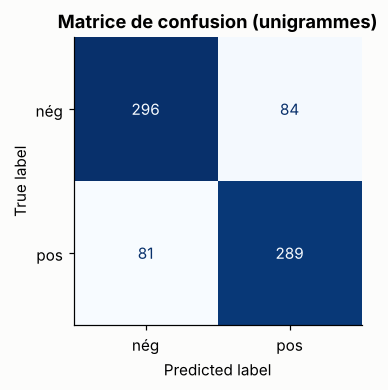

In [17]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

pred = clf1.predict(vec1.transform(X_te_txt))
print(classification_report(y_te, pred, target_names=["négatif", "positif"], digits=3))
fig, ax = plt.subplots(figsize=(3.8, 3.4))
ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["nég", "pos"]).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Matrice de confusion (unigrammes)"); ax.grid(False)
plt.show()

## 10. Passage à PyTorch et aux tokenizers de Hugging Face

### 10.1 Le même classifieur en PyTorch

Une régression logistique sur TF-IDF n'est qu'une couche `nn.Linear` sur un vecteur creux. Plus intéressant : `nn.EmbeddingBag`, qui fait **embedding + moyenne** en une seule opération efficace, sans padding (on passe tous les tokens concaténés et des *offsets* de début de chaque document). C'est l'architecture de **fastText**.

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

tok = lambda s: re.findall(r"\w+|[^\w\s]", s.lower())
vocab_ft = Vocab([t for s in X_tr_txt for t in tok(s)], min_freq=1, specials=("[PAD]", "[UNK]", "[BOS]", "[EOS]"))

def add_bigrams(toks):
    return toks + [a + "_" + b for a, b in zip(toks, toks[1:])]

vocab_bi = Vocab([t for s in X_tr_txt for t in add_bigrams(tok(s))], min_freq=2)


def to_bag_batch(sentences, vocab, use_bigrams):
    ids, offsets = [], []
    for s in sentences:
        toks = add_bigrams(tok(s)) if use_bigrams else tok(s)
        offsets.append(len(ids))
        ids.extend(vocab.encode(toks))
    return torch.tensor(ids, dtype=torch.long), torch.tensor(offsets, dtype=torch.long)


class FastTextClassifier(nn.Module):
    def __init__(self, vocab_size, d=32, n_classes=2):
        super().__init__()
        self.bag = nn.EmbeddingBag(vocab_size, d, mode="mean")
        self.out = nn.Linear(d, n_classes)

    def forward(self, ids, offsets):
        return self.out(self.bag(ids, offsets))


def train_fasttext(use_bigrams, epochs=15, bs=64, lr=5e-3, seed=0):
    torch.manual_seed(seed)
    vocab = vocab_bi if use_bigrams else vocab_ft
    model = FastTextClassifier(len(vocab))
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    y_train = torch.tensor(y_tr, dtype=torch.long)
    for ep in range(epochs):
        perm = torch.randperm(len(X_tr_txt))
        model.train()
        for k in range(0, len(perm), bs):
            idx = perm[k:k + bs].tolist()
            ids, offsets = to_bag_batch([X_tr_txt[i] for i in idx], vocab, use_bigrams)
            loss = F.cross_entropy(model(ids, offsets), y_train[idx])
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        ids, offsets = to_bag_batch(X_te_txt, vocab, use_bigrams)
        acc = (model(ids, offsets).argmax(-1).numpy() == y_te).mean()
    return model, acc

for bi in [False, True]:
    _, acc = train_fasttext(bi)
    print(f"fastText-style, bigrams={bi}: test accuracy {acc:.3f}")

### 10.2 Les tokenizers des vrais modèles

La librairie `transformers` charge le tokenizer exact de chaque modèle pré-entraîné. Compare comment différents modèles découpent la même phrase française :

In [ ]:
from transformers import AutoTokenizer

sentence = "L'anticonstitutionnalité de cette tokenisation est incompréhensible 🤯."
for name in ["gpt2", "bert-base-multilingual-cased", "camembert-base"]:
    tk = AutoTokenizer.from_pretrained(name)
    pieces = tk.tokenize(sentence)
    print(f"{name:30s} {len(pieces):2d} tokens: {pieces}")

tk = AutoTokenizer.from_pretrained("camembert-base")
enc = tk(["Le film est génial.", "Le film n'est pas génial du tout."], padding=True, return_tensors="pt")
print(enc["input_ids"])
print(enc["attention_mask"])          # the same padding mask we built by hand in module 1
print(tk.convert_ids_to_tokens(enc["input_ids"][1]))

**Ce que tu dois observer** : GPT-2 (BPE byte-level entraîné sur de l'anglais) découpe le français en beaucoup de morceaux, et affiche des symboles comme `Ġ` (espace encodé) ou des octets bruts pour les accents et l'emoji. CamemBERT (SentencePiece entraîné sur du français) produit des découpages plus courts et plus « morphologiques », avec `▁` pour marquer le début d'un mot. **Un tokenizer inadapté à la langue (ou au domaine : code, protéines, chimie) gaspille de la longueur de contexte et dégrade le modèle.**

### 10.3 Entraîner son propre BPE en une seconde

In [ ]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

bpe_tok = Tokenizer(models.BPE(unk_token="[UNK]"))
bpe_tok.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.BpeTrainer(vocab_size=2000, special_tokens=["[PAD]", "[UNK]", "[CLS]", "[SEP]", "[MASK]"])
bpe_tok.train_from_iterator(words_doc, trainer=trainer)       # the pydoc corpus from section 3
print(bpe_tok.encode("Tokenization of parameterized functions").tokens)

## 11. Récapitulatif

| Notion | À retenir |
|---|---|
| Normalisation | Unicode NFC toujours ; le reste (minuscules, accents) est un choix qui détruit de l'information |
| Zipf | $f \propto 1/r$ : quelques mots très fréquents, une longue traîne de mots rares |
| Sous-mots | BPE / WordPiece / Unigram : pas d'inconnus, vocabulaire de 30–250 k |
| BPE | fusionner itérativement la paire la plus fréquente ; encoder en rejouant les fusions dans l'ordre |
| Compromis | vocabulaire plus grand ↔ séquences plus courtes |
| Tokens spéciaux | PAD, UNK, BOS/EOS, CLS, SEP, MASK |
| Sac de mots / TF-IDF | vecteur creux de taille $V$ ; ignore l'ordre ; idf pénalise les mots ubiquitaires |
| Évaluation | précision, rappel, F1 ; macro vs micro ; analyser les erreurs |
| Fuite de données | ajuster vocabulaire/idf/normalisation **sur le train uniquement** |

### 🏋️ Exercices

1. **Byte-level BPE.** Modifie `train_bpe` pour qu'il opère sur les octets UTF-8 (`list(word.encode("utf-8"))`) plutôt que sur les caractères. Vérifie qu'un mot avec emoji ou caractères chinois est encodable sans `[UNK]`.
2. **Décodage.** Écris `bpe_decode(tokens)` qui reconstruit le texte à partir des sous-mots (indice : le marqueur `</w>`).
3. **Zipf en français.** Génère 3 000 critiques avec `make_review` et trace la loi de Zipf. Pourquoi la courbe est-elle très différente d'un vrai corpus ? (Que dit-elle sur les limites des données synthétiques ?)
4. **Classes déséquilibrées.** Ne garde que 10 % des critiques positives. Compare accuracy et macro-F1 de la régression logistique avec et sans `class_weight="balanced"`.
5. **Ordre des mots.** Trouve une paire de critiques de sens opposé que même le modèle à trigrammes ne peut pas distinguer. Que faudrait-il au modèle ?

<details><summary>Indications</summary>

1. Les symboles de base deviennent des entiers 0–255 ; une fusion produit un tuple d'octets ; vocabulaire initial = 256.
2. `"".join(tokens).replace("</w>", " ").strip()`.
3. Le vocabulaire est minuscule (~70 mots) et les fréquences sont fixées par les gabarits : pas de longue traîne. Les données synthétiques testent un mécanisme, jamais une performance réelle.
4. Avec un fort déséquilibre, l'accuracy reste élevée alors que le rappel de la classe minoritaire s'effondre ; `class_weight` repondère la perte par l'inverse des fréquences.
5. « A est excellent, mais B est raté » vs « B est raté, mais A est excellent » avec des sujets identiques : il faut un modèle séquentiel qui sait que la proposition après « mais » domine.
</details>

**➡️ Module suivant : les word embeddings** (hypothèse distributionnelle, word2vec skip-gram avec échantillonnage négatif codé de zéro, visualisation de l'espace sémantique, `nn.Embedding`).